# BT4012 Competition — Supervised Learning

Continues from `02_preprocessing.ipynb`. Trains on the 31,235 rows with a genuine label and predicts on `test.csv` (`time_step` 36–49, all later than anything in `train`). The competition metric is **ROC-AUC**, so every score in this notebook is ROC-AUC.

**Final model** (section 4, `data/submissions/final_submission.csv`): XGBoost on genuine labels only, with recency-weighted training (`half_life=10`) and tuned hyperparameters, using the 45 features with the highest SHAP impact (leaderboard ROC-AUC 0.95483).

How the notebook is organized:
1. **Setup**: load data and build a temporal validation split (train on `time_step` ≤ 30, validate on 31–35).
2. **Baseline models**: Random Forest, XGBoost, LightGBM and Logistic Regression. The two gradient-boosting models lead.
3. **Diagnosing the validation–leaderboard gap**: XGBoost's ~0.998 validation ROC-AUC became 0.94 on the leaderboard, because what illicit transactions look like drifts over time. Recency-weighted training partly counters it (leaderboard 0.94 → 0.949), and adversarial validation shows which features carry the time signal.
4. **Final model and submission**, plus SHAP feature importance.
5. **LightGBM**: compared with XGBoost on equal footing, tuned, cut down by SHAP and blended with XGBoost. None of these beat the XGBoost submission on the leaderboard.
6. **Neural network (MLP)**: scaling and size compared, the MLP set against XGBoost on both splits, and blended with it.

**Appendix**: experiments that didn't beat the final model on the leaderboard, kept with their results so the reasoning is on record.

`time_step` is never a model input: every test row's `time_step` is outside the training range, and tree models can't extrapolate beyond a feature's observed range.

In [1]:
import itertools
import warnings

import numpy as np
from lightgbm import LGBMClassifier
import pandas as pd
from scipy.stats import spearmanr
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import GridSearchCV, PredefinedSplit, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 20)

## 1. Setup

Load the reduced feature set from `02_preprocessing.ipynb`. Only rows with a genuine label are used for training and validation.

In [2]:
train_reduced = pd.read_csv("data/processed/train_reduced.csv")
test_reduced = pd.read_csv("data/processed/test_reduced.csv")

# Model features: everything except identifiers/time, the label itself, and the
# propagated-label columns from 02_preprocessing.ipynb (those are candidate extra
# training *rows*, not input features — see appendix A1).
feat_cols = [c for c in train_reduced.columns
             if c not in ("txId", "time_step", "label", "label_propagated", "label_propagated_confidence")]

labeled = train_reduced[train_reduced["label"].notna()].copy()
labeled["label"] = labeled["label"].astype(int)

print("model features:", len(feat_cols))
print("labeled rows:", len(labeled), f"(illicit {labeled['label'].mean():.2%})")
print("test rows:", len(test_reduced))

model features: 85
labeled rows: 31235 (illicit 11.67%)
test rows: 15329


### Temporal validation split

Train on `time_step` ≤ 30, validate on 31–35. Validation is strictly later than training, which mirrors the real train → test direction. A random split would let future rows inform predictions about the past and give optimistic numbers.

In [3]:
SPLIT_POINT = 30

train_df = labeled[labeled["time_step"] <= SPLIT_POINT]
val_df = labeled[labeled["time_step"] > SPLIT_POINT]

X_train, y_train = train_df[feat_cols], train_df["label"]
X_val, y_val = val_df[feat_cols], val_df["label"]

print(f"train: {len(train_df)} rows (illicit {y_train.mean():.2%})")
print(f"val:   {len(val_df)} rows (illicit {y_val.mean():.2%})")

train: 26905 rows (illicit 10.98%)
val:   4330 rows (illicit 15.94%)


## 2. Baseline models

### Random Forest

`class_weight="balanced"` re-weights the loss inversely to class frequency, since illicit is only ~11% of labeled rows.

In [4]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_val_proba = rf.predict_proba(X_val)[:, 1]
rf_val_pred = rf.predict(X_val)

print(confusion_matrix(y_val, rf_val_pred))
print(classification_report(y_val, rf_val_pred, digits=3))
print("ROC-AUC:", roc_auc_score(y_val, rf_val_proba))

[[3634    6]
 [ 188  502]]
              precision    recall  f1-score   support

           0      0.951     0.998     0.974      3640
           1      0.988     0.728     0.838       690

    accuracy                          0.955      4330
   macro avg      0.970     0.863     0.906      4330
weighted avg      0.957     0.955     0.952      4330

ROC-AUC: 0.9973194378085682


#### Random Forest hyperparameter tuning

`GridSearchCV`'s default `cv` does random/stratified k-fold, which would let training folds contain rows from *after* validation-fold rows in `time_step` — the same "future leaks into past" problem the temporal split exists to avoid. Instead, `PredefinedSplit` forces exactly one fold: train on `train_df` (`time_step` ≤ 30), score on `val_df` (`time_step` > 30), so results are directly comparable to every other model here.

In [5]:
# One predefined fold: -1 = never held out (train), 0 = validation fold.
X_gs = pd.concat([X_train, X_val])
y_gs = pd.concat([y_train, y_val])
test_fold = np.concatenate([np.full(len(X_train), -1), np.zeros(len(X_val))])
ps = PredefinedSplit(test_fold)

param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20],
    "max_features": ["sqrt", "log2"],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": ["balanced", "balanced_subsample"],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=1),
    param_grid=param_grid,
    scoring="roc_auc",  # the competition metric — matches how every other model here is judged
    cv=ps,
    n_jobs=-1,
    refit=False,  # we retrain manually below, on train_df only, to report val metrics without leakage
    verbose=1,
)
grid_search.fit(X_gs, y_gs)

print("candidates tried:", len(grid_search.cv_results_["params"]))
print("best params:", grid_search.best_params_)
print("best ROC-AUC (validation fold):", grid_search.best_score_)

Fitting 1 folds for each of 108 candidates, totalling 108 fits
candidates tried: 108
best params: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}
best ROC-AUC (validation fold): 0.9973335722248766


In [6]:
rf_tuned = RandomForestClassifier(**grid_search.best_params_, random_state=42, n_jobs=-1)
rf_tuned.fit(X_train, y_train)

rf_tuned_val_proba = rf_tuned.predict_proba(X_val)[:, 1]
rf_tuned_val_pred = rf_tuned.predict(X_val)

print(confusion_matrix(y_val, rf_tuned_val_pred))
print(classification_report(y_val, rf_tuned_val_pred, digits=3))
print("ROC-AUC:", roc_auc_score(y_val, rf_tuned_val_proba))

[[3634    6]
 [ 192  498]]
              precision    recall  f1-score   support

           0      0.950     0.998     0.973      3640
           1      0.988     0.722     0.834       690

    accuracy                          0.954      4330
   macro avg      0.969     0.860     0.904      4330
weighted avg      0.956     0.954     0.951      4330

ROC-AUC: 0.9973335722248766


### XGBoost

`scale_pos_weight` is the standard XGBoost equivalent of `class_weight="balanced"` — the ratio of majority to minority class counts in the training fold.

In [7]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    scale_pos_weight=scale_pos_weight, eval_metric="logloss",
    random_state=42, n_jobs=-1,
)
xgb.fit(X_train, y_train)

xgb_val_proba = xgb.predict_proba(X_val)[:, 1]
xgb_val_pred = xgb.predict(X_val)

print(confusion_matrix(y_val, xgb_val_pred))
print(classification_report(y_val, xgb_val_pred, digits=3))
print("ROC-AUC:", roc_auc_score(y_val, xgb_val_proba))

[[3605   35]
 [  28  662]]
              precision    recall  f1-score   support

           0      0.992     0.990     0.991      3640
           1      0.950     0.959     0.955       690

    accuracy                          0.985      4330
   macro avg      0.971     0.975     0.973      4330
weighted avg      0.986     0.985     0.985      4330

ROC-AUC: 0.9976714046822743


### Logistic Regression (a non-tree baseline)

Random Forest and XGBoost are both tree-based: bagging and boosting differ, but both split on feature thresholds and can share blind spots. Logistic Regression draws a linear boundary instead, and suits this feature set: the VIF pruning in `02_preprocessing.ipynb` exists to fix multicollinearity, which matters for linear models and not for trees.

Features are standardized first, since Logistic Regression is sensitive to feature scale. The scaler is fit on `X_train` only, so no validation statistics leak into training.

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

logreg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)

logreg_val_proba = logreg.predict_proba(X_val_scaled)[:, 1]
logreg_val_pred = logreg.predict(X_val_scaled)

print(confusion_matrix(y_val, logreg_val_pred))
print(classification_report(y_val, logreg_val_pred, digits=3))
print("ROC-AUC:", roc_auc_score(y_val, logreg_val_proba))

[[2249 1391]
 [  63  627]]
              precision    recall  f1-score   support

           0      0.973     0.618     0.756      3640
           1      0.311     0.909     0.463       690

    accuracy                          0.664      4330
   macro avg      0.642     0.763     0.609      4330
weighted avg      0.867     0.664     0.709      4330

ROC-AUC: 0.8688991081382386


In [9]:
# Interpretability bonus, unavailable from the tree models: which features push toward "illicit" vs. "licit"?
coef_report = pd.Series(logreg.coef_[0], index=feat_cols).sort_values()

print("strongest push toward licit (negative):")
print(coef_report.head(5))
print("\nstrongest push toward illicit (positive):")
print(coef_report.tail(5))

strongest push toward licit (negative):
feat_5    -8.185969
feat_59   -7.672718
feat_22   -6.320653
feat_18   -5.594887
feat_82   -5.581202
dtype: float64

strongest push toward illicit (positive):
feat_160      1.493889
feat_108      1.526804
feat_121      1.552772
hop2_reach    1.776146
feat_76       1.880401
dtype: float64


### LightGBM

Another gradient-boosting library. LightGBM grows each tree leaf by leaf, always splitting whichever leaf most reduces the loss, where XGBoost grows level by level. That lets it fit more complex patterns with the same number of leaves. It uses the same class weighting as XGBoost (`scale_pos_weight`) and 300 trees, with LightGBM's defaults for everything else. Its hyperparameters are tuned separately on the gap-matched split in `04_tuning.ipynb` (step 5); section 5 follows up on the tuned models.

In [10]:
lgbm = LGBMClassifier(n_estimators=300, scale_pos_weight=scale_pos_weight, random_state=42, n_jobs=-1, verbose=-1)
lgbm.fit(X_train, y_train)

lgbm_val_proba = lgbm.predict_proba(X_val)[:, 1]
lgbm_val_pred = lgbm.predict(X_val)

print(confusion_matrix(y_val, lgbm_val_pred))
print(classification_report(y_val, lgbm_val_pred, digits=3))
print("ROC-AUC:", roc_auc_score(y_val, lgbm_val_proba))

[[3604   36]
 [  15  675]]
              precision    recall  f1-score   support

           0      0.996     0.990     0.993      3640
           1      0.949     0.978     0.964       690

    accuracy                          0.988      4330
   macro avg      0.973     0.984     0.978      4330
weighted avg      0.988     0.988     0.988      4330

ROC-AUC: 0.9981043956043956


### Comparison

| Model | Illicit precision | Illicit recall | Illicit F1 | ROC-AUC |
|---|---|---|---|---|
| Random Forest | 0.988 | 0.728 | 0.838 | 0.9973 |
| XGBoost | 0.950 | 0.959 | 0.955 | 0.9977 |
| **LightGBM** | 0.949 | **0.978** | **0.964** | **0.9981** |
| Logistic Regression | 0.311 | 0.909 | 0.463 | 0.8689 |

**The two gradient-boosting models lead**, mainly on recall: Random Forest is precise when it flags a transaction but misses over a quarter of illicit ones. LightGBM edges XGBoost here, but ROC-AUC is close to its ceiling on this window, so the gap between them (0.9981 vs. 0.9977) is too small to separate them.

**XGBoost is used for the final model** because its full recipe (section 4) is the one confirmed on the leaderboard (0.95483). LightGBM is followed up in section 5: tuned versions and an XGBoost + LightGBM blend, none of which beat it on the leaderboard.

Logistic Regression is far weaker (better regularization raises its ROC-AUC to about 0.93, still well below the trees), so the illicit/licit boundary here is genuinely nonlinear. It stays in as a reference point, not as a candidate model.

## 3. Diagnosing the validation–leaderboard gap: temporal drift

XGBoost's ~0.998 validation ROC-AUC became 0.94 on the leaderboard. The real test set (`time_step` 36–49) sits further from the training data than the validation window (31–35) does, and what illicit transactions look like drifts over `time_step`.

### Recency-weighted training

Down-weight older labeled rows during training, rather than treating every `time_step` ≤ 30 as equally representative of what the model will face at 36–49.

`recency_weight = 0.5 ** ((SPLIT_POINT - time_step) / half_life)` gives rows at `time_step` == `SPLIT_POINT` a weight of 1.0, halving every `half_life` steps further back. XGBoost only exposes a single global `scale_pos_weight`, so the class ratio is baked into a combined per-row weight instead.

The final model uses `half_life=10`, which raised the leaderboard ROC-AUC from 0.94 to 0.949. On this validation window every setting scores ROC-AUC ≈ 0.998: the window is only 1–5 steps past training, so it's close to saturated and shows far less of the drift than the real 36–49 test period.

In [11]:
print("baseline (no recency weight) XGBoost  ROC-AUC:", roc_auc_score(y_val, xgb_val_proba))
print()

for half_life in [5, 10, 20, 40]:
    recency_weight = 0.5 ** ((SPLIT_POINT - train_df["time_step"]) / half_life)

    class_weight_map = {0: 1.0, 1: scale_pos_weight}
    combined_weight = y_train.map(class_weight_map) * recency_weight

    xgb_rw = XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        eval_metric="logloss", random_state=42, n_jobs=-1,
    )
    xgb_rw.fit(X_train, y_train, sample_weight=combined_weight)

    xgb_rw_val_proba = xgb_rw.predict_proba(X_val)[:, 1]
    xgb_rw_val_pred = xgb_rw.predict(X_val)

    print(f"half_life={half_life}")
    print(confusion_matrix(y_val, xgb_rw_val_pred))
    print("ROC-AUC:", roc_auc_score(y_val, xgb_rw_val_proba))
    print()

baseline (no recency weight) XGBoost  ROC-AUC: 0.9976714046822743

half_life=5
[[3590   50]
 [  16  674]]
ROC-AUC: 0.9972682752030579

half_life=10
[[3602   38]
 [  17  673]]
ROC-AUC: 0.9976086956521738

half_life=20
[[3612   28]
 [  22  668]]
ROC-AUC: 0.99787585602803

half_life=40
[[3606   34]
 [  19  671]]
ROC-AUC: 0.99815535913362



### Which features carry the time signal? (adversarial validation)

Train a classifier to tell `time_step` ≤ 30 rows apart from `time_step` > 30 rows using **only the features, ignoring `label` entirely**. If it succeeds, its feature importances (`drift_importance`) show which features reveal the time period. Dropping the most time-revealing ones is tested in appendix A2; it didn't help on the leaderboard.

In [12]:
adv_target = (labeled["time_step"] > SPLIT_POINT).astype(int)  # 1 = "late" (time_step > 30), 0 = "early"
X_adv = labeled[feat_cols]

X_adv_train, X_adv_test, y_adv_train, y_adv_test = train_test_split(
    X_adv, adv_target, test_size=0.3, stratify=adv_target, random_state=42
)

adv_clf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
adv_clf.fit(X_adv_train, y_adv_train)
adv_auc = roc_auc_score(y_adv_test, adv_clf.predict_proba(X_adv_test)[:, 1])

print(f"adversarial (early vs. late time_step) ROC-AUC: {adv_auc:.4f}")
print("(0.5 = features look identical across time; higher = features carry a time signature)")

adversarial (early vs. late time_step) ROC-AUC: 1.0000
(0.5 = features look identical across time; higher = features carry a time signature)


In [13]:
# Cross-reference drift-importance against label-relevance (computed on train_df only, matching 02_preprocessing.ipynb's convention):
# a feature high in drift-importance but low in label-relevance is close to pure "era" noise — a strong drop candidate.
drift_importance = pd.Series(adv_clf.feature_importances_, index=feat_cols)
label_relevance = train_df[feat_cols].corrwith(train_df["label"]).abs()

drift_report = pd.DataFrame({
    "drift_importance": drift_importance,
    "label_corr": label_relevance,
}).sort_values("drift_importance", ascending=False)

print(drift_report.head(15))

drift_threshold = drift_report["drift_importance"].quantile(0.75)
relevance_threshold = drift_report["label_corr"].median()

drop_candidates = drift_report[
    (drift_report["drift_importance"] >= drift_threshold) & (drift_report["label_corr"] <= relevance_threshold)
].index.tolist()

print(f"\n{len(drop_candidates)} drop candidates (high drift-importance, below-median label relevance):")
print(drop_candidates)

                          drift_importance  label_corr
feat_136                          0.327906    0.179493
feat_103                          0.316285    0.194330
feat_2                            0.068981    0.023234
feat_142                          0.033376    0.185216
feat_112                          0.032281    0.177884
community_internal_ratio          0.026551    0.038450
community_density                 0.025568    0.084646
community_size                    0.023340    0.188125
feat_109                          0.022641    0.058109
feat_3                            0.015859    0.047390
feat_148                          0.010021    0.195927
feat_144                          0.007081    0.095549
closeness                         0.005254    0.171825
feat_54                           0.004975    0.180534
feat_130                          0.004019    0.045963

5 drop candidates (high drift-importance, below-median label relevance):
['feat_2', 'community_internal_ratio', 'feat_1

## 4. Final model and submission

### Final model

For the submission, XGBoost is retrained on **all** 31,235 labeled rows (`time_step` 1–35), since every known label helps before predicting the unseen 36–49.

- **Recency weighting, `half_life=10`**, anchored at `time_step` 35. Leaderboard 0.94 → 0.949 over the unweighted model.
- **Hyperparameters** `max_depth=4, learning_rate=0.1, subsample=1.0, colsample_bytree=0.7, reg_lambda=5`, chosen in the original tuning sweep. A re-run of the sweep on the current 85 features (`04_tuning.ipynb`) preferred `learning_rate=0.2, colsample_bytree=1.0, reg_lambda=1` (gap-matched ROC-AUC 0.881 → 0.900), but that version scored lower on the leaderboard (0.94936 vs. 0.95430), so these more regularized settings were kept.
- **SHAP feature selection**: train on all 85 features, rank them by mean |SHAP|, keep the top 45 and retrain on those. `04_tuning.ipynb` (step 4) tested cuts from 75 down to 35 features on the gap-matched split; top 45 was the only one that didn't lose to all 85 (ROC-AUC 0.882 vs. 0.881). On the leaderboard it scored 0.95483, against 0.95430 for all 85 features: about the same score with half the features.

`BEST_PARAMS` and `FINAL_HALF_LIFE` are defined here and reused by sections 5–6 and the appendix.

In [14]:
X_full, y_full = labeled[feat_cols], labeled["label"]
scale_pos_weight_full = (y_full == 0).sum() / (y_full == 1).sum()

FINAL_HALF_LIFE = 10
final_cutoff = labeled["time_step"].max()  # 35 — most recent labeled time_step
recency_weight_full = 0.5 ** ((final_cutoff - labeled["time_step"]) / FINAL_HALF_LIFE)
class_weight_map_full = {0: 1.0, 1: scale_pos_weight_full}
combined_weight_full = y_full.map(class_weight_map_full) * recency_weight_full

BEST_PARAMS = dict(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=1.0,
                   colsample_bytree=0.7, reg_lambda=5, eval_metric="logloss", random_state=42, n_jobs=-1)
N_FINAL_FEATURES = 45

# Rank all features by mean |SHAP| in a model trained on all of them, then keep the top 45.
# final_cols stays in SHAP-rank order: colsample_bytree samples columns by position, so order affects the model.
full_model = XGBClassifier(**BEST_PARAMS)
full_model.fit(X_full, y_full, sample_weight=combined_weight_full)
full_shap = pd.Series(np.abs(shap.TreeExplainer(full_model).shap_values(X_full)).mean(axis=0), index=feat_cols)
final_cols = list(full_shap.sort_values(ascending=False).index[:N_FINAL_FEATURES])

final_model = XGBClassifier(**BEST_PARAMS)
final_model.fit(labeled[final_cols], y_full, sample_weight=combined_weight_full)

test_proba = final_model.predict_proba(test_reduced[final_cols])[:, 1]
print(f"final model: {len(final_cols)} of {len(feat_cols)} features")
print("predicted illicit share on test:", (test_proba >= 0.5).mean())

final model: 45 of 85 features
predicted illicit share on test: 0.04462130602126688


### Submission file

`sample_submission.csv` expects `index` = the 0-based row position in `test.csv`, and `target` = the predicted probability of illicit. `test_reduced.csv` preserves `test.csv`'s row order, so a positional index lines up. An identical copy is also saved as `data/submissions/experiments/submission_xgb_recency_weighted.csv`.

In [15]:
submission = pd.DataFrame({
    "index": np.arange(len(test_reduced)),
    "target": test_proba,
})
submission.to_csv("data/submissions/final_submission.csv", index=False)
submission.to_csv("data/submissions/experiments/submission_xgb_recency_weighted.csv", index=False)

print("saved data/submissions/final_submission.csv (and an identical copy, data/submissions/experiments/submission_xgb_recency_weighted.csv):", submission.shape)
submission.head()

saved data/submissions/final_submission.csv (and an identical copy, data/submissions/experiments/submission_xgb_recency_weighted.csv): (15329, 2)


,index,target
0,0,0.001053
1,1,0.005271
2,2,0.002808
3,3,0.000848
4,4,0.000531


### What drives the final model? (SHAP)

SHAP values for `final_model` (the 45 selected features), computed over all 31,235 labeled training rows. Mean |SHAP| ranks features by how much they move predictions on average; the beeswarm also shows direction (red = high feature value; pushing right = toward illicit).

Each feature's `drift_importance` from section 3 is shown next to it. A feature that ranks high on both is used heavily by the model *and* reveals the time period.

          mean_abs_shap  shap_share  drift_importance
feat_53          1.4174      0.1185            0.0026
feat_59          1.2742      0.1065            0.0028
feat_2           0.5974      0.0499            0.0690
feat_5           0.5838      0.0488            0.0014
feat_89          0.5813      0.0486            0.0031
feat_16          0.5129      0.0429            0.0027
feat_125         0.4841      0.0405            0.0020
feat_25          0.4765      0.0398            0.0014
feat_3           0.3932      0.0329            0.0159
feat_83          0.3311      0.0277            0.0016
feat_18          0.3053      0.0255            0.0019
feat_161         0.3019      0.0252            0.0009
feat_64          0.2980      0.0249            0.0004
feat_163         0.2707      0.0226            0.0007
feat_76          0.2467      0.0206            0.0004


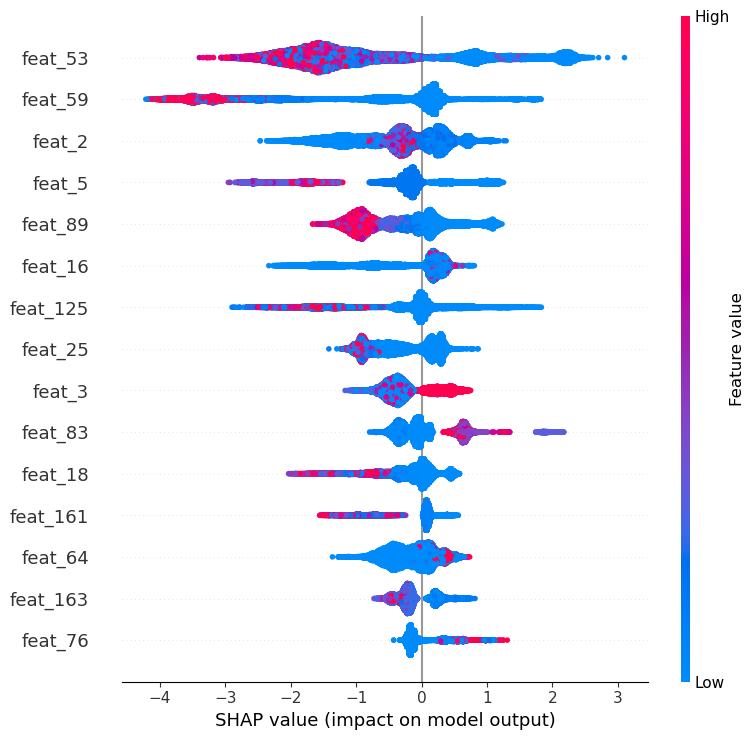

In [16]:
X_final = labeled[final_cols]
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_final)

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=final_cols).sort_values(ascending=False)
shap_report = pd.DataFrame({
    "mean_abs_shap": mean_abs_shap,
    "shap_share": mean_abs_shap / mean_abs_shap.sum(),
    "drift_importance": drift_importance.reindex(mean_abs_shap.index),
})
print(shap_report.head(15).round(4))

shap.summary_plot(shap_values, X_final, max_display=15, show=True)

In [17]:
# The most time-revealing features (section 3): which made it into the final 45, and how much the model uses them.
shap_report["shap_rank"] = np.arange(1, len(shap_report) + 1)
top_drift = drift_importance.sort_values(ascending=False).head(10)
print(pd.DataFrame({
    "drift_importance": top_drift,
    "in_final_model": top_drift.index.isin(final_cols),
    "shap_rank": shap_report["shap_rank"].reindex(top_drift.index),
    "shap_share": shap_report["shap_share"].reindex(top_drift.index),
}).round(4))

                          drift_importance  in_final_model  shap_rank  \
feat_136                            0.3279            True       26.0   
feat_103                            0.3163            True       21.0   
feat_2                              0.0690            True        3.0   
feat_142                            0.0334            True       39.0   
feat_112                            0.0323           False        NaN   
community_internal_ratio            0.0266            True       27.0   
community_density                   0.0256            True       42.0   
community_size                      0.0233            True       43.0   
feat_109                            0.0226            True       36.0   
feat_3                              0.0159            True        9.0   

                          shap_share  
feat_136                      0.0116  
feat_103                      0.0148  
feat_2                        0.0499  
feat_142                      0.0081  
f

## 5. LightGBM

LightGBM edged XGBoost among the baselines (section 2), so it was explored further. Everything here uses the same sample weights as the final model: class balance times recency (`half_life=10`).

Two validation splits are used here and in section 6 (`val_splits`):
- **Gap-matched**: train on `time_step` 1–20, validate on 30–35. The 10-step gap is closer to the real distance between training and the test period (as in `04_tuning.ipynb`).
- **Adjacent**: the section 1 split (train 1–30, validate 31–35), for reference. ROC-AUC sits near its ceiling here, so it rarely separates models.

### 5.1 LightGBM vs. XGBoost on all 85 features

Both algorithms on equal footing, before any SHAP-based selection:
- **XGBoost (final recipe)**: `BEST_PARAMS` from section 4.
- **LightGBM (mirrored)**: set up to match it as closely as possible: depth 4 (at most 15 leaves), learning rate 0.1, 70% of features per tree, `reg_lambda=5`.
- **LightGBM (defaults)**: LightGBM's own defaults (31 leaves, no depth limit, no feature sampling or regularization).

All use 300 trees.

In [18]:
val_splits = {
    "gap-matched (train 1-20, validate 30-35)": (labeled[labeled["time_step"] <= 20],
                                                  labeled[labeled["time_step"].between(30, 35)]),
    "adjacent (train 1-30, validate 31-35)": (train_df, val_df),
}
gap_train, gap_val = val_splits["gap-matched (train 1-20, validate 30-35)"]


def recency_class_weight(rows):
    # Class balance times recency, anchored at the latest time_step in rows (same recipe as the final model).
    # Shared by sections 5 and 6.
    y = rows["label"]
    class_ratio = (y == 0).sum() / (y == 1).sum()
    recency = 0.5 ** ((rows["time_step"].max() - rows["time_step"]) / FINAL_HALF_LIFE)
    return y.map({0: 1.0, 1: class_ratio}) * recency


lgbm_candidates = {
    "XGBoost (final recipe)": lambda: XGBClassifier(**BEST_PARAMS),
    "LightGBM (mirrored)": lambda: LGBMClassifier(
        n_estimators=300, max_depth=4, num_leaves=15, learning_rate=0.1, colsample_bytree=0.7,
        reg_lambda=5, random_state=42, n_jobs=-1, verbose=-1),
    "LightGBM (defaults)": lambda: LGBMClassifier(
        n_estimators=300, random_state=42, n_jobs=-1, verbose=-1),
}

lgbm_vs_xgb = {}
for model_name, make_model in lgbm_candidates.items():
    for split_name, (tr, va) in val_splits.items():
        model = make_model()
        model.fit(tr[feat_cols], tr["label"], sample_weight=recency_class_weight(tr))
        lgbm_vs_xgb[(model_name, split_name)] = roc_auc_score(va["label"], model.predict_proba(va[feat_cols])[:, 1])

lgbm_vs_xgb = pd.Series(lgbm_vs_xgb).unstack()
lgbm_vs_xgb.index.name = "ROC-AUC"
lgbm_vs_xgb.round(4)

,"adjacent (train 1-30, validate 31-35)","gap-matched (train 1-20, validate 30-35)"
ROC-AUC,,
LightGBM (defaults),0.9982,0.8455
LightGBM (mirrored),0.9956,0.8535
XGBoost (final recipe),0.9971,0.8809


Out of the box, neither LightGBM setting matches XGBoost on the gap-matched split, so LightGBM needs its own tuning rather than XGBoost's settings.

### 5.2 Tuned LightGBM submissions

The two most promising configurations from the LightGBM grid in `04_tuning.ipynb` (step 5), on all 85 features:

| Config | `num_leaves` | `learning_rate` | `subsample` | `colsample_bytree` | `reg_lambda` | Gap-matched ROC-AUC | Leaderboard |
|---|---|---|---|---|---|---|---|
| #1 | 31 | 0.2 | 0.7 | 0.7 | 1 | 0.8964 | 0.93907 |
| #2 | 7 | 0.05 | 1.0 | 0.7 | 5 | 0.8902 | 0.95286 |

The final XGBoost recipe scores 0.8809 on the same split and 0.95483 on the leaderboard. #1 is the grid's top score but the least regularized, and like the XGBoost tuning winner it lost on the leaderboard. #2 follows the conservative pattern (small trees, slow learning rate) and came close to XGBoost without beating it.

Each configuration's gap-matched score is re-checked first, then the model is retrained on all labeled data and its test predictions are exported. `data/submissions/final_submission.csv` is not touched.

In [19]:
LGBM_TUNED = {
    "submission_lgbm_leaves31.csv": dict(num_leaves=31, learning_rate=0.2, subsample=0.7, colsample_bytree=0.7, reg_lambda=1),
    "submission_lgbm_leaves7.csv": dict(num_leaves=7, learning_rate=0.05, subsample=1.0, colsample_bytree=0.7, reg_lambda=5),
}


def make_tuned_lgbm(params):
    return LGBMClassifier(n_estimators=300, subsample_freq=1, random_state=42, n_jobs=-1, verbose=-1, **params)


for filename, params in LGBM_TUNED.items():
    check = make_tuned_lgbm(params).fit(gap_train[feat_cols], gap_train["label"], sample_weight=recency_class_weight(gap_train))
    gap_auc = roc_auc_score(gap_val["label"], check.predict_proba(gap_val[feat_cols])[:, 1])

    tuned = make_tuned_lgbm(params).fit(labeled[feat_cols], labeled["label"], sample_weight=recency_class_weight(labeled))
    target = tuned.predict_proba(test_reduced[feat_cols])[:, 1]
    pd.DataFrame({"index": np.arange(len(test_reduced)), "target": target}).to_csv(f"data/submissions/experiments/{filename}", index=False)
    print(f"{filename}: gap-matched ROC-AUC {gap_auc:.4f}; predicted illicit share on test {(target >= 0.5).mean():.2%}")

submission_lgbm_leaves31.csv: gap-matched ROC-AUC 0.8964; predicted illicit share on test 4.03%
submission_lgbm_leaves7.csv: gap-matched ROC-AUC 0.8902; predicted illicit share on test 5.31%


### 5.3 SHAP-based feature reduction for LightGBM #2

Cutting XGBoost to its top 45 features by SHAP nudged its leaderboard score up (0.95430 → 0.95483). This runs the same test for LightGBM #2 (7 leaves), using LightGBM's own SHAP ranking, since its important features may differ from XGBoost's.

For validation, the ranking comes from a model trained only on the gap-matched training rows (`time_step` 1–20), so the choice of features never sees the validation labels. Cuts tested: keep the top 75 / 65 / 55 / 45 / 35, against all 85. The best cut is then exported, with features ranked by the model trained on all labeled data. `data/submissions/final_submission.csv` is not touched.

In [20]:
def fit_lgbm2(rows, cols):
    return make_tuned_lgbm(LGBM_TUNED["submission_lgbm_leaves7.csv"]).fit(
        rows[cols], rows["label"], sample_weight=recency_class_weight(rows))


def shap_ranking(model, rows, cols):
    values = shap.TreeExplainer(model).shap_values(rows[cols])
    if isinstance(values, list):  # older shap versions return one array per class
        values = values[1]
    return pd.Series(np.abs(values).mean(axis=0), index=cols).sort_values(ascending=False)


def lgbm2_gap_auc(cols):
    model = fit_lgbm2(gap_train, cols)
    return roc_auc_score(gap_val["label"], model.predict_proba(gap_val[cols])[:, 1])


gap_ranking = shap_ranking(fit_lgbm2(gap_train, feat_cols), gap_train, feat_cols)
cuts = {"all 85": lgbm2_gap_auc(feat_cols)}
for n in [75, 65, 55, 45, 35]:
    cuts[f"top {n}"] = lgbm2_gap_auc(list(gap_ranking.index[:n]))

cut_results = pd.Series(cuts, name="gap-matched ROC-AUC")
print(cut_results.round(4).to_string())
best_cut = cut_results.drop("all 85").idxmax()
best_n = int(best_cut.split()[1])
print(f"\nbest cut: {best_cut} ({cut_results[best_cut] - cut_results['all 85']:+.4f} vs. all 85)")

/opt/anaconda3/lib/python3.12/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


all 85    0.8902
top 75    0.8793
top 65    0.8857
top 55    0.8815
top 45    0.8762
top 35    0.8654

best cut: top 65 (-0.0044 vs. all 85)


In [21]:
full_ranking = shap_ranking(fit_lgbm2(labeled, feat_cols), labeled, feat_cols)
lgbm_cols = list(full_ranking.index[:best_n])

lgbm2_reduced = fit_lgbm2(labeled, lgbm_cols)
target = lgbm2_reduced.predict_proba(test_reduced[lgbm_cols])[:, 1]
filename = f"submission_lgbm_leaves7_top{best_n}.csv"
pd.DataFrame({"index": np.arange(len(test_reduced)), "target": target}).to_csv(f"data/submissions/experiments/{filename}", index=False)

print(f"saved data/submissions/experiments/{filename}: {best_n} features; predicted illicit share on test {(target >= 0.5).mean():.2%}")

/opt/anaconda3/lib/python3.12/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


saved data/submissions/experiments/submission_lgbm_leaves7_top65.csv: 65 features; predicted illicit share on test 5.26%


Unlike XGBoost, every cut loses to all 85 features on the gap-matched split, so LightGBM #2 is best left on the full set.

### 5.4 XGBoost + LightGBM ensemble

Blends the final XGBoost recipe with LightGBM #2 (7 leaves, all 85 features), the two strongest leaderboard results (0.95483 and 0.95286). Predictions are converted to percentile ranks and averaged: ROC-AUC only scores the ordering, and the two models' probabilities sit on different scales. A blend can only help where the models disagree, so their rank correlation is shown too.

**Validation** uses both splits, with XGBoost on all 85 features: its 45-feature selection used every label, including the validation rows.

**Submissions** blend the exact two files already scored on the leaderboard (`submission_shap_top45.csv` and `submission_lgbm_leaves7.csv`): a 50/50 blend, and a 70/30 blend leaning toward XGBoost, since it scored higher.

In [22]:
blend_rows = []
for split_name, (tr, va) in val_splits.items():
    xgb_model = XGBClassifier(**BEST_PARAMS).fit(tr[feat_cols], tr["label"], sample_weight=recency_class_weight(tr))
    lgbm_model = fit_lgbm2(tr, feat_cols)
    r_xgb = pd.Series(xgb_model.predict_proba(va[feat_cols])[:, 1]).rank(pct=True)
    r_lgbm = pd.Series(lgbm_model.predict_proba(va[feat_cols])[:, 1]).rank(pct=True)
    print(f"{split_name}: Spearman correlation between the models {spearmanr(r_xgb, r_lgbm).correlation:.4f}")
    for w in [1.0, 0.7, 0.5, 0.3, 0.0]:
        blend_rows.append({"split": split_name, "XGBoost weight": w,
                           "ROC-AUC": roc_auc_score(va["label"], w * r_xgb + (1 - w) * r_lgbm)})

pd.DataFrame(blend_rows).pivot(index="XGBoost weight", columns="split", values="ROC-AUC").sort_index(ascending=False).round(4)

gap-matched (train 1-20, validate 30-35): Spearman correlation between the models 0.9177
adjacent (train 1-30, validate 31-35): Spearman correlation between the models 0.9642


split,"adjacent (train 1-30, validate 31-35)","gap-matched (train 1-20, validate 30-35)"
XGBoost weight,,
1.0,0.9971,0.8809
0.7,0.9969,0.8838
0.5,0.9966,0.8859
0.3,0.9962,0.8879
0.0,0.9955,0.8902


In [23]:
xgb_sub = pd.read_csv("data/submissions/experiments/submission_shap_top45.csv")
lgbm_sub = pd.read_csv("data/submissions/experiments/submission_lgbm_leaves7.csv")
assert (xgb_sub["index"] == lgbm_sub["index"]).all()

t_xgb = xgb_sub["target"].rank(pct=True)
t_lgbm = lgbm_sub["target"].rank(pct=True)
print(f"test set: Spearman correlation between the two submissions {spearmanr(t_xgb, t_lgbm).correlation:.4f}")

for w, filename in [(0.5, "submission_xgb_lgbm_rank50.csv"), (0.7, "submission_xgb_lgbm_rank70.csv")]:
    pd.DataFrame({"index": xgb_sub["index"], "target": w * t_xgb + (1 - w) * t_lgbm}).to_csv(f"data/submissions/experiments/{filename}", index=False)
    print(f"saved data/submissions/experiments/{filename} (XGBoost weight {w})")

test set: Spearman correlation between the two submissions 0.9420
saved data/submissions/experiments/submission_xgb_lgbm_rank50.csv (XGBoost weight 0.5)
saved data/submissions/experiments/submission_xgb_lgbm_rank70.csv (XGBoost weight 0.7)


The two models agree closely (rank correlation above 0.9), and on validation each blend lands between its two parents rather than above both. On the leaderboard the blends didn't meaningfully improve on XGBoost alone, so **the final model stays XGBoost** (section 4).

## 6. Neural network (MLP)

Every model so far is tree-based or linear. This section tries a feed-forward neural network: scikit-learn's `MLPClassifier`, on all 85 features, with the same splits (section 5) and the same sample weights (class balance times recency, `half_life=10`).

Two things differ from the tree models:
- **Scaling.** Trees ignore feature scale, but a neural network needs inputs on a comparable scale. Many features here are heavy-tailed, so two options are compared, both fitted on the training rows only: `StandardScaler` (clipped to ±5) and `QuantileTransformer`, which maps each feature onto a normal distribution by rank.
- **Randomness.** Results depend on the random initialisation, so every network here is the average of several networks trained with different seeds (3 for comparisons, 5 for the final model). Training runs for a fixed 40 passes over the data with an L2 penalty of 0.01; the sample weights are rescaled to average 1 so the step size stays sensible.

### 6.1 Scaling and network size

In [24]:
def fit_mlp_ensemble(rows, cols, hidden=(64,), scaler="quantile", seeds=range(5)):
    # Fits one MLP per seed and returns a function that averages their predicted probabilities.
    if scaler == "quantile":
        transform = QuantileTransformer(output_distribution="normal", random_state=0).fit(rows[cols])
        prep = transform.transform
    else:
        transform = StandardScaler().fit(rows[cols])
        prep = lambda X: np.clip(transform.transform(X), -5, 5)
    weight = recency_class_weight(rows)
    weight = (weight / weight.mean()).to_numpy()
    X = prep(rows[cols])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)  # fixed 40 passes, by design
        models = [MLPClassifier(hidden_layer_sizes=hidden, alpha=0.01, batch_size=256, max_iter=40, random_state=seed)
                  .fit(X, rows["label"], sample_weight=weight) for seed in seeds]
    return lambda new_rows: np.mean([m.predict_proba(prep(new_rows[cols]))[:, 1] for m in models], axis=0)


mlp_rows = []
for scaler, hidden in itertools.product(["standard", "quantile"], [(64,), (128, 64)]):
    for split_name, (tr, va) in val_splits.items():
        predict = fit_mlp_ensemble(tr, feat_cols, hidden=hidden, scaler=scaler, seeds=range(3))
        mlp_rows.append({"scaling": scaler, "hidden layers": str(hidden), "split": split_name,
                         "ROC-AUC": roc_auc_score(va["label"], predict(va))})

print("XGBoost (final recipe), for comparison:")
print(lgbm_vs_xgb.loc["XGBoost (final recipe)"].round(4).to_string(), "\n")
pd.DataFrame(mlp_rows).pivot(index=["scaling", "hidden layers"], columns="split", values="ROC-AUC").round(4)

XGBoost (final recipe), for comparison:
adjacent (train 1-30, validate 31-35)       0.9971
gap-matched (train 1-20, validate 30-35)    0.8809 



split                   adjacent (train 1-30, validate 31-35)  \
scaling  hidden layers                                          
quantile (128, 64)                                     0.9470   
         (64,)                                         0.9596   
standard (128, 64)                                     0.9411   
         (64,)                                         0.9588   

split                   gap-matched (train 1-20, validate 30-35)  
scaling  hidden layers                                            
quantile (128, 64)                                        0.8783  
         (64,)                                            0.9032  
standard (128, 64)                                        0.8559  
         (64,)                                            0.8615

The quantile transform is clearly better than standard scaling, and one hidden layer of 64 units does at least as well as two layers. That combination is used from here on. The finer settings (L2 penalty, layer width) were not tuned against the gap-matched split, since section 5 showed that small gains there don't carry over to the leaderboard.

### 6.2 MLP vs. XGBoost, and blending them

The MLP is the average of 5 seeds. Blends average percentile ranks, as in section 5.4.

In [25]:
nn_blend_rows = []
for split_name, (tr, va) in val_splits.items():
    xgb_model = XGBClassifier(**BEST_PARAMS).fit(tr[feat_cols], tr["label"], sample_weight=recency_class_weight(tr))
    r_xgb = pd.Series(xgb_model.predict_proba(va[feat_cols])[:, 1]).rank(pct=True)
    r_mlp = pd.Series(fit_mlp_ensemble(tr, feat_cols)(va)).rank(pct=True)
    print(f"{split_name}: Spearman correlation between the models {spearmanr(r_xgb, r_mlp).correlation:.4f}")
    for w in [1.0, 0.7, 0.5, 0.3, 0.0]:
        nn_blend_rows.append({"split": split_name, "XGBoost weight": w,
                              "ROC-AUC": roc_auc_score(va["label"], w * r_xgb + (1 - w) * r_mlp)})

pd.DataFrame(nn_blend_rows).pivot(index="XGBoost weight", columns="split", values="ROC-AUC").sort_index(ascending=False).round(4)

gap-matched (train 1-20, validate 30-35): Spearman correlation between the models 0.7114
adjacent (train 1-30, validate 31-35): Spearman correlation between the models 0.8241


split,"adjacent (train 1-30, validate 31-35)","gap-matched (train 1-20, validate 30-35)"
XGBoost weight,,
1.0,0.9971,0.8809
0.7,0.9917,0.8879
0.5,0.9857,0.8925
0.3,0.9778,0.8965
0.0,0.9620,0.8988


The two splits disagree. On the gap-matched split, where training ends 10 steps before validation, the MLP beats XGBoost on its own. On the adjacent split it is well behind. The MLP seems to learn smoother patterns that age better but are less sharp in the short term. Unlike LightGBM, it ranks transactions quite differently from XGBoost (rank correlation around 0.7–0.8, against above 0.9 for LightGBM), which is what a blend needs.

The test period sits 1–14 steps after the training data, between the two validation settings, so neither split settles this. The leaderboard has to.

### 6.3 Submissions

The MLP is retrained on all labeled rows (5 seeds) and exported on its own. It is also blended with the final XGBoost submission (`final_submission.csv`) at XGBoost weights 0.7 and 0.5. `data/submissions/final_submission.csv` is not touched.

In [26]:
mlp_target = fit_mlp_ensemble(labeled, feat_cols)(test_reduced)
pd.DataFrame({"index": np.arange(len(test_reduced)), "target": mlp_target}).to_csv(
    "data/submissions/experiments/submission_mlp.csv", index=False)
print(f"saved data/submissions/experiments/submission_mlp.csv: predicted illicit share on test {(mlp_target >= 0.5).mean():.2%}")

final_sub = pd.read_csv("data/submissions/final_submission.csv")
assert (final_sub["index"] == np.arange(len(test_reduced))).all()
t_xgb = final_sub["target"].rank(pct=True)
t_mlp = pd.Series(mlp_target).rank(pct=True)
print(f"test set: Spearman correlation between XGBoost and the MLP {spearmanr(t_xgb, t_mlp).correlation:.4f}")

for w, filename in [(0.7, "submission_xgb_mlp_rank70.csv"), (0.5, "submission_xgb_mlp_rank50.csv")]:
    pd.DataFrame({"index": final_sub["index"], "target": w * t_xgb + (1 - w) * t_mlp}).to_csv(
        f"data/submissions/experiments/{filename}", index=False)
    print(f"saved data/submissions/experiments/{filename} (XGBoost weight {w})")

saved data/submissions/experiments/submission_mlp.csv: predicted illicit share on test 4.64%
test set: Spearman correlation between XGBoost and the MLP 0.6839
saved data/submissions/experiments/submission_xgb_mlp_rank70.csv (XGBoost weight 0.7)
saved data/submissions/experiments/submission_xgb_mlp_rank50.csv (XGBoost weight 0.5)


**Leaderboard**: `submission_mlp.csv` scored 0.91393 and the 70/30 blend (`submission_xgb_mlp_rank70.csv`) scored 0.95098, both below XGBoost alone (0.95483). The 50/50 blend was not submitted. The adjacent split predicted both losses, in direction and roughly in size (MLP: −0.035 on validation, −0.041 on the leaderboard); the gap-matched split pointed the wrong way. The MLP is the most different partner tried so far, but it is too weak on its own for a blend to help, so **the final model stays XGBoost** (section 4).

## Appendix: experiments that didn't beat the final model

Each idea below looked reasonable, was validated on genuine labels only, and scored worse than `data/submissions/final_submission.csv` on the leaderboard. They're kept with their results so the reasoning is on record. They were run before the final model was cut to 45 features, so they use all 85.

Tested elsewhere: the Random Forest + XGBoost blend (`05_ensemble.ipynb`) and a stricter 0.8 duplicate threshold (`02_preprocessing.ipynb`, step 1). Neither improved on the final model.


### A1. Pseudo-labels from label propagation

`02_preprocessing.ipynb` fit `LabelPropagation` on all 31,235 genuine labels plus the 110,537 unlabeled rows, producing `label_propagated` and `label_propagated_confidence` for every row. Here, unlabeled rows with confidence ≥ 0.95 or ≥ 0.99 are added to the *training* set on top of the final recipe, and scored on the genuine 31–35 labels.

**Outcome:** no gain on validation at either threshold, and both pseudo-label submissions scored worse than `final_submission.csv` on the leaderboard.

In [27]:
def pseudo_pool_at(threshold):
    pool = train_reduced[
        train_reduced["label"].isna() & (train_reduced["label_propagated_confidence"] >= threshold)
    ].copy()
    pool["label"] = pool["label_propagated"].astype(int)
    return pool


def fit_and_score(train_rows, val_rows, cutoff, label=""):
    X_tr, y_tr = train_rows[feat_cols], train_rows["label"]
    X_va, y_va = val_rows[feat_cols], val_rows["label"]

    spw = (y_tr == 0).sum() / (y_tr == 1).sum()
    recency = 0.5 ** ((cutoff - train_rows["time_step"]) / FINAL_HALF_LIFE)
    weight = y_tr.map({0: 1.0, 1: spw}) * recency

    model = XGBClassifier(**BEST_PARAMS)
    model.fit(X_tr, y_tr, sample_weight=weight)
    proba = model.predict_proba(X_va)[:, 1]

    print(f"{label}: {len(train_rows)} train rows  "
          f"ROC-AUC: {roc_auc_score(y_va, proba):.4f}")
    return model


print("--- Adjacent window (train <=30, validate on real 31-35) ---")
fit_and_score(train_df, val_df, SPLIT_POINT, "real only")
for threshold in [0.95, 0.99]:
    pool = pseudo_pool_at(threshold)
    extra = pool[pool["time_step"] <= SPLIT_POINT]
    fit_and_score(pd.concat([train_df, extra], ignore_index=True), val_df, SPLIT_POINT,
                  f"real + {len(extra)} pseudo (>= {threshold})")


--- Adjacent window (train <=30, validate on real 31-35) ---
real only: 26905 train rows  ROC-AUC: 0.9971
real + 37082 pseudo (>= 0.95): 63987 train rows  ROC-AUC: 0.9640
real + 29911 pseudo (>= 0.99): 56816 train rows  ROC-AUC: 0.9858


#### Pseudo-label submissions

The final recipe trained on genuine labels plus pseudo-labels at each threshold, exported as `data/submissions/experiments/submission_xgb_pseudo095.csv` and `data/submissions/experiments/submission_xgb_pseudo099.csv`. Using propagated labels doesn't leak into `test.csv`, which was never part of propagation — but both scored worse than `final_submission.csv` on the leaderboard.

In [28]:
for threshold, filename in [(0.95, "submission_xgb_pseudo095.csv"), (0.99, "submission_xgb_pseudo099.csv")]:
    pool = pseudo_pool_at(threshold)
    full_with_pseudo = pd.concat([labeled, pool], ignore_index=True)
    X_full_pseudo, y_full_pseudo = full_with_pseudo[feat_cols], full_with_pseudo["label"]

    spw_pseudo = (y_full_pseudo == 0).sum() / (y_full_pseudo == 1).sum()
    recency_pseudo = 0.5 ** ((final_cutoff - full_with_pseudo["time_step"]) / FINAL_HALF_LIFE)
    weight_pseudo = y_full_pseudo.map({0: 1.0, 1: spw_pseudo}) * recency_pseudo

    model = XGBClassifier(**BEST_PARAMS)
    model.fit(X_full_pseudo, y_full_pseudo, sample_weight=weight_pseudo)
    proba = model.predict_proba(test_reduced[feat_cols])[:, 1]

    pd.DataFrame({"index": np.arange(len(test_reduced)), "target": proba}).to_csv(f"data/submissions/experiments/{filename}", index=False)

    print(f"threshold {threshold}: {len(labeled)} real + {len(pool)} pseudo "
          f"({(pool['label'] == 1).sum()} illicit) = {len(full_with_pseudo)} rows; "
          f"predicted illicit share on test {(proba >= 0.5).mean():.2%}; saved data/submissions/experiments/{filename}")

threshold 0.95: 31235 real + 41486 pseudo (5472 illicit) = 72721 rows; predicted illicit share on test 5.32%; saved data/submissions/experiments/submission_xgb_pseudo095.csv
threshold 0.99: 31235 real + 33003 pseudo (4077 illicit) = 64238 rows; predicted illicit share on test 5.43%; saved data/submissions/experiments/submission_xgb_pseudo099.csv


### A2. Dropping high-drift features

Drop the features adversarial validation (section 3) found most time-revealing: drift importance ≥ 0.05 (`feat_2`, `feat_103`, `feat_136`) or ≥ 0.019 (adds `feat_3`, `feat_109`, `feat_112`, `feat_142`). `feat_2` was the main candidate, since SHAP ranks it both heavily used and time-dependent.

**Outcome:** both versions scored worse than `final_submission.csv` on the leaderboard. A feature that drifts within `time_step` 1–35 can still be useful for 36–49.

In [29]:
for cutoff, filename in [(0.019, "submission_xgb_dropdrift0019.csv"), (0.05, "submission_xgb_dropdrift005.csv")]:
    cols = [c for c in feat_cols if drift_importance[c] < cutoff]

    model = XGBClassifier(**BEST_PARAMS)
    model.fit(labeled[cols], y_full, sample_weight=combined_weight_full)
    proba = model.predict_proba(test_reduced[cols])[:, 1]

    pd.DataFrame({"index": np.arange(len(test_reduced)), "target": proba}).to_csv(f"data/submissions/experiments/{filename}", index=False)
    print(f"drift < {cutoff}: {len(cols)} features; predicted illicit share on test {(proba >= 0.5).mean():.2%}; "
          f"saved data/submissions/experiments/{filename}")

drift < 0.019: 76 features; predicted illicit share on test 5.47%; saved data/submissions/experiments/submission_xgb_dropdrift0019.csv
drift < 0.05: 82 features; predicted illicit share on test 5.21%; saved data/submissions/experiments/submission_xgb_dropdrift005.csv


### A3. Slower recency decay (`half_life=20`)

The final recipe with `half_life=20`: the oldest labeled row keeps `0.5 ** (34/20) ≈ 30%` of its weight, vs. ≈9% at `half_life=10`. Exported as `data/submissions/experiments/submission_xgb_recency_hl20.csv`. An earlier version (before hyperparameter tuning) scored below `half_life=10` on the leaderboard.

In [30]:
HALF_LIFE_20 = 20
recency_weight_hl20 = 0.5 ** ((final_cutoff - labeled["time_step"]) / HALF_LIFE_20)
combined_weight_hl20 = y_full.map(class_weight_map_full) * recency_weight_hl20

final_model_hl20 = XGBClassifier(**BEST_PARAMS)
final_model_hl20.fit(X_full, y_full, sample_weight=combined_weight_hl20)

test_proba_hl20 = final_model_hl20.predict_proba(test_reduced[feat_cols])[:, 1]

submission_xgb_hl20 = pd.DataFrame({
    "index": np.arange(len(test_reduced)),
    "target": test_proba_hl20,
})
submission_xgb_hl20.to_csv("data/submissions/experiments/submission_xgb_recency_hl20.csv", index=False)

print("predicted illicit share on test (half_life=20):", (test_proba_hl20 >= 0.5).mean())
print("saved data/submissions/experiments/submission_xgb_recency_hl20.csv:", submission_xgb_hl20.shape)
submission_xgb_hl20.head()

predicted illicit share on test (half_life=20): 0.044882249331332766
saved data/submissions/experiments/submission_xgb_recency_hl20.csv: (15329, 2)


,index,target
0,0,0.001154
1,1,0.019660
2,2,0.002273
3,3,0.002235
4,4,0.000054


### A4. Random Forest submission

Random Forest trained on all labeled data, exported as `data/submissions/experiments/submission_rf.csv` for comparison. It was consistently weaker than XGBoost on validation (section 2).

In [31]:
final_rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
final_rf.fit(X_full, y_full)
rf_test_proba = final_rf.predict_proba(test_reduced[feat_cols])[:, 1]

submission_rf = pd.DataFrame({
    "index": np.arange(len(test_reduced)),
    "target": rf_test_proba,
})
submission_rf.to_csv("data/submissions/experiments/submission_rf.csv", index=False)

print("predicted illicit share on test (Random Forest):", (rf_test_proba >= 0.5).mean())
print("saved data/submissions/experiments/submission_rf.csv:", submission_rf.shape)

predicted illicit share on test (Random Forest): 0.031182725552873637
saved data/submissions/experiments/submission_rf.csv: (15329, 2)
